In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

(40, 1)
(40,)
[[0.        ]
 [0.25641026]
 [0.51282051]
 [0.76923077]
 [1.02564103]]
[4.48357077 1.3415516  5.36993513 9.91100727 1.35520288]
Polynomial degree: 1
Training MSE: 42.90
Testing MSE: 42.99

Polynomial degree: 2
Training MSE: 20.44
Testing MSE: 19.79

Polynomial degree: 10
Training MSE: 12.89
Testing MSE: 95.22



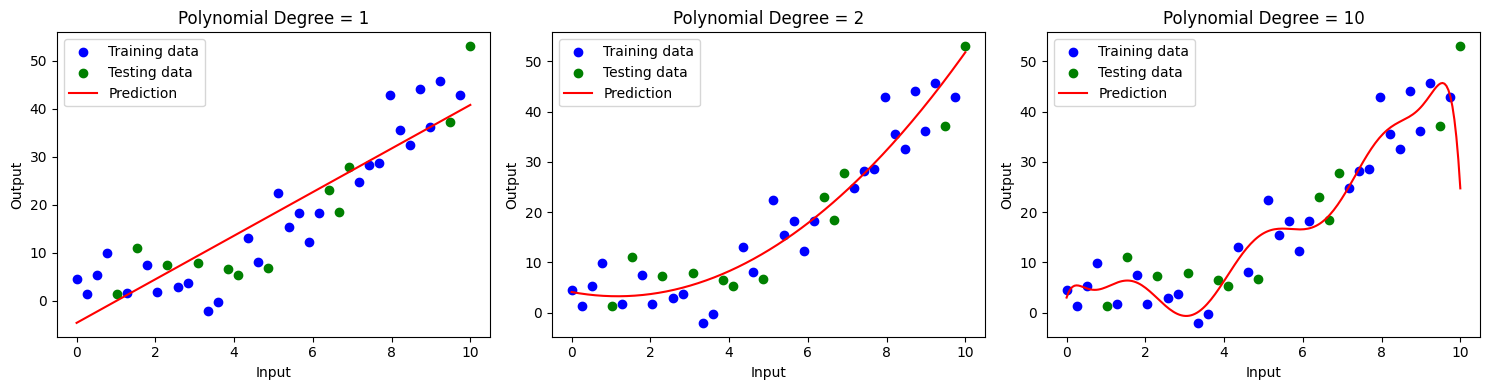

In [10]:
np.random.seed(42)
x=np.linspace(0,10,40).reshape(-1,1)
y=2+0.5*x[:,0]**2 +np.random.normal(0,5,40)
print(x.shape)
print(y.shape)

print(x[:5])
print(y[:5])


x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=42)
degrees=[1,2,10]

for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(x_train, y_train)

    train_prediction = model.predict(x_train)
    test_prediction = model.predict(x_test)

    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)

    print(f"Polynomial degree: {degree}")
    print(f"Training MSE: {train_mse:.2f}")
    print(f"Testing MSE: {test_mse:.2f}")
    print()

x_plot = np.linspace(0, 10, 200).reshape(-1, 1)

plt.figure(figsize=(15, 4))

for index, degree in enumerate(degrees):

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(x_train, y_train)
    y_plot = model.predict(x_plot)

    plt.subplot(1, 3, index + 1)

    plt.scatter(x_train, y_train, color="blue", label="Training data")
    plt.scatter(x_test, y_test, color="green", label="Testing data")
    plt.plot(x_plot, y_plot, color="red", label="Prediction")

    plt.title(f"Polynomial Degree = {degree}")
    plt.xlabel("Input")
    plt.ylabel("Output")
    plt.legend()

plt.tight_layout()
plt.show()


In [16]:
from sklearn.model_selection import cross_val_score


for degree in range(1,11):

    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    scores=cross_val_score(
        model,
        x,
        y,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    mean_mse = -scores.mean()

    print(f"Degree {degree}: CV MSE = {mean_mse:.2f}")
    model.fit(x_train, y_train)

    train_prediction = model.predict(x_train)
    test_prediction = model.predict(x_test)

    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)

    print(f"Polynomial degree: {degree}")
    print(f"Training MSE: {train_mse:.2f}")
    print(f"Testing MSE: {test_mse:.2f}")
    print()


Degree 1: CV MSE = 110.69
Polynomial degree: 1
Training MSE: 42.90
Testing MSE: 42.99

Degree 2: CV MSE = 44.22
Polynomial degree: 2
Training MSE: 20.44
Testing MSE: 19.79

Degree 3: CV MSE = 71.23
Polynomial degree: 3
Training MSE: 18.46
Testing MSE: 22.45

Degree 4: CV MSE = 82.46
Polynomial degree: 4
Training MSE: 17.75
Testing MSE: 22.36

Degree 5: CV MSE = 1348.27
Polynomial degree: 5
Training MSE: 17.43
Testing MSE: 19.87

Degree 6: CV MSE = 11392.13
Polynomial degree: 6
Training MSE: 16.07
Testing MSE: 34.16

Degree 7: CV MSE = 53226.76
Polynomial degree: 7
Training MSE: 16.03
Testing MSE: 36.91

Degree 8: CV MSE = 99956.80
Polynomial degree: 8
Training MSE: 14.32
Testing MSE: 21.72

Degree 9: CV MSE = 1196598.08
Polynomial degree: 9
Training MSE: 14.31
Testing MSE: 22.84

Degree 10: CV MSE = 11490573.91
Polynomial degree: 10
Training MSE: 12.89
Testing MSE: 95.22

